In [16]:

import numpy as np
import pyvrp as vrp
import pandas as pd



In [17]:
data_nodos=pd.read_excel(r'Datos/data.xlsx', sheet_name=0)

data_vehiculos=pd.read_excel(r'Datos/data.xlsx', sheet_name=1)

data_nodos.head()


,Nodos,Coor_X,Coor_Y,Demanda,Tiemp_Serv,Horario_aper,Horario_cierre
0,Nodo_0,15,84,0,NaN,NaN,NaN
1,Nodo_1,20,65,5,NaN,NaN,NaN
2,Nodo_2,25,32,8,NaN,NaN,NaN
3,Nodo_3,15,38,9,NaN,NaN,NaN
4,Nodo_4,98,4,4,NaN,NaN,NaN


In [18]:
data_vehiculos.head()

,Tipo,Cantidad,Capacidad
0,Vehiculo_0,5,8
1,Vehiculo_1,2,20
2,Vehiculo_2,3,15
3,Vehiculo_3,2,12


In [19]:
data_nodos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Nodos           24 non-null     object 
 1   Coor_X          24 non-null     int64  
 2   Coor_Y          24 non-null     int64  
 3   Demanda         24 non-null     int64  
 4   Tiemp_Serv      0 non-null      float64
 5   Horario_aper    0 non-null      float64
 6   Horario_cierre  0 non-null      float64
dtypes: float64(3), int64(3), object(1)
memory usage: 1.4+ KB


In [20]:
m=vrp.Model()

m.add_depot(x=data_nodos.iloc[0,1],y=data_nodos.iloc[0,2])


In [21]:
for i in range(1,len(data_nodos['Nodos'])):
    m.add_client(x=data_nodos.iloc[i,1],y=data_nodos.iloc[i,2], delivery=int(data_nodos.iloc[i,3]))


In [22]:
data_vehiculos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Tipo       4 non-null      object
 1   Cantidad   4 non-null      int64 
 2   Capacidad  4 non-null      int64 
dtypes: int64(2), object(1)
memory usage: 228.0+ bytes


In [23]:
data_vehiculos.iloc[1,2]

20

In [24]:
for j in range(0,len(data_vehiculos['Tipo'])):
    m.add_vehicle_type(num_available=int(data_vehiculos.iloc[j,1]), capacity=int(data_vehiculos.iloc[j,2]), start_depot=m.locations[0], end_depot=m.locations[0], reload_depots=[m.locations[0]])

In [25]:
for frm_idx, frm in enumerate(m.locations):
    for to_idx, to in enumerate(m.locations):
        m.add_edge(frm, to, distance=abs(frm.x - to.x) + abs(frm.y - to.y))

In [26]:
vehiculos=m.vehicle_types
vehiculos[2].capacity

[15]

In [27]:


from pyvrp.stop import MaxRuntime

res = m.solve(stop=MaxRuntime(60), display=True, seed=27)



PyVRP v0.11.3

Solving an instance with:
    1 depot
    23 clients
    12 vehicles (4 vehicle types)

                  |       Feasible        |      Infeasible
    Iters    Time |   #      Avg     Best |   #      Avg     Best
H     500      1s |  54     1503     1366 |  31     1242     1171
     1000      1s |  40     1469     1366 |  39     1325     1279
     1500      2s |  28     1457     1366 |  47     1246     1199
     2000      3s |  34     1454     1366 |  55     1227     1199
     2500      3s |  46     1473     1366 |  63     1348     1295
     3000      4s |  30     1465     1366 |  30     1326     1294
     3500      4s |  47     1486     1366 |  38     1336     1294
     4000      5s |  41     1475     1366 |  46     1328     1294
     4500      6s |  34     1452     1366 |  53     1335     1294
     5000      6s |  57     1480     1366 |  61     1337     1294
     5500      7s |  56     1470     1366 |  27     1328     1294
     6000      7s |  31     1440     1366 |  

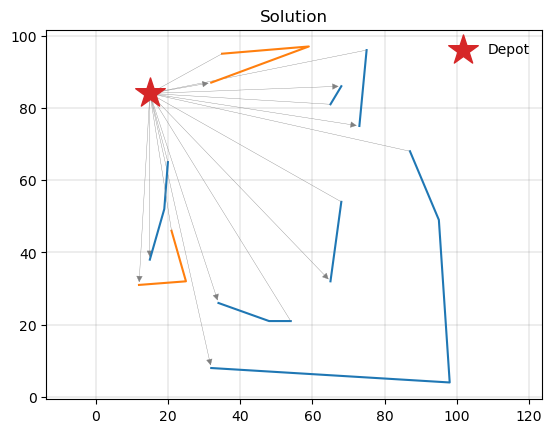

In [28]:
from pyvrp import plotting

plotting.plot_solution(res.best, m.data())

In [29]:
print(res)

Solution results
    # routes: 2
     # trips: 8
   # clients: 23
   objective: 1366
    distance: 1366
    duration: 0
# iterations: 49339
    run-time: 60.00 seconds

Routes
------
Route #1: 16 6 12 | 3 15 1 | 21 14 | 18 7 | 9 5 19 | 8 4 10 11
Route #2: 13 22 17 | 20 2 23



In [31]:
sol=res.best
rutas= sol.routes()
print(rutas[1].vehicle_type())

1
